# Progetto Finale: Riconoscimento Gesti della Mano

## Titolo: Sviluppo di una CNN con Data Augmentation per Sasso, Carta, Forbici

### 1. Obiettivo del Progetto

L'obiettivo è sviluppare il "cervello" visivo per un videogioco interattivo. Dovrai progettare e addestrare un'Intelligenza Artificiale basata su una **Rete Neurale Convoluzionale (CNN)** capace di classificare istantaneamente le immagini catturate dalla webcam in tre categorie: **Sasso**, **Carta** o **Forbice**.

### 2. Risorse: Il Dataset

Per questo progetto utilizzeremo il dataset **Rock-Paper-Scissors (CGI)**, composto da oltre 2.500 immagini sintetiche di mani in varie pose su sfondo bianco.

- **Training Set:** Scarica rps.zip
- **Test Set:** Scarica rps-test-set.zip

> **Nota:** Le immagini sono organizzate in sottocartelle corrispondenti alle classi (`/rock`, `/paper`, `/scissors`). Il caricamento deve rispettare questa struttura gerarchica.

In [2]:
import os
os.environ['KERAS_BACKEND'] = 'torch'
import keras
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.metrics import classification_report, confusion_matrix

# NOTA in Keras 3 (versione installata 3.15) ImageDataGenerator è stato tolto
# dall'API pubblica, quindi "from keras.preprocessing.image import ImageDataGenerator" dà errore.
# Il codice originale è ancora presente nel modulo legacy di Keras: lo importo da lì
# per usare la classe richiesta dalla traccia.
from keras.src.legacy.preprocessing.image import ImageDataGenerator

In [3]:
# --- PERCORSI E PARAMETRI ---
# I dataset sono già estratti in queste cartelle: rps/ e rps-test-set/,
# ognuno con le sottocartelle paper/, rock/, scissors/
TRAIN_DIR = 'rps'
TEST_DIR = 'rps-test-set'
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

### 3. Roadmap di Sviluppo

#### Fase A: Data Pipeline e Augmentation

Utilizza la classe `ImageDataGenerator` di Keras per gestire il flusso di dati. È richiesto di implementare la **Data Augmentation** per rendere il modello robusto alle variazioni di posizione e orientamento.

- **Normalizzazione:** Imposta `rescale=1./255`.
- **Trasformazioni obbligatorie:**
    - `rotation_range=40`
    - `width_shift_range=0.2`
    - `shear_range=0.2`
    - `horizontal_flip=True`
    - `fill_mode='nearest'`

In [ ]:
# --- FASE A: GENERATOR DI TRAINING ---
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
) 

train_generator = train_datagen.flow_from_directory(TRAIN_DIR,
                                                    target_size=IMG_SIZE,
                                                    batch_size=BATCH_SIZE,
                                                    class_mode='categorical') 

# --- FASE A: GENERATOR DI TEST ---
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(TEST_DIR,
                                                  target_size=IMG_SIZE,
                                                  batch_size=BATCH_SIZE,
                                                  class_mode='categorical',
                                                  shuffle=False) 

# --- CONTROLLO CLASSI E TARGET NAMES ---
print(train_generator.class_indices)


Found 2520 images belonging to 3 classes.
Found 372 images belonging to 3 classes.
{'paper': 0, 'rock': 1, 'scissors': 2}


#### Fase B: Architettura della Rete (CNN)

Progetta una rete neurale sequenziale con i seguenti requisiti tecnici:

1. **Input Layer:** Immagini con dimensione 150x150 pixel a 3 canali (RGB).
2. **Blocchi Convoluzionali:** Almeno 3 o 4 livelli `Conv2D` alternati a livelli `MaxPooling2D`. Aumenta progressivamente il numero di filtri (es. 32 -> 64 -> 128).
3. **Livelli Dens:** Un livello `Flatten` seguito da un livello `Dense` con almeno 512 neuroni e attivazione `relu`.
4. **Output Layer:** Un livello `Dense` con **3 neuroni** e attivazione **Softmax**.

In [6]:
# --- FASE B: ARCHITETTURA ---
def build_rps_model():
    model = keras.Sequential([
        keras.Input(shape=(150, 150, 3)),
        keras.layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2,2)),
        keras.layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2,2)),
        keras.layers.Conv2D(filters=128, kernel_size=(3,3), activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2,2)),
        keras.layers.Conv2D(filters=128, kernel_size=(3,3), activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2,2)),
        keras.layers.Flatten(),
        keras.layers.Dense(512, activation='relu'),
        keras.layers.Dense(3, activation='softmax')
        ])

    return model

model = build_rps_model()
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,454,147 (13.18 MB)

 Trainable params: 3,454,147 (13.18 MB)

 Non-trainable params: 0 (0.00 B)

#### Fase C: Compilazione e Training

Configura il processo di addestramento con i seguenti parametri:

- **Optimizer:** `Adam` o `RMSprop`.
- **Loss Function:** `categorical_crossentropy`.
- **Metriche:** `accuracy`.
- **Epoche:** Esegui il training per 15-20 epoche.
- **Callback:** Implementa una `EarlyStopping` o una callback personalizzata per interrompere l'addestramento se l'accuratezza supera il 98%.

In [ ]:
# --- FASE C: COMPILAZIONE ---

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
# --- FASE C: CALLBACKS ---

early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss',
                                               patience=5,
                                               restore_best_weights=True)

rps_checkpoint = keras.callbacks.ModelCheckpoint('rps_checkpoint.keras', save_best_only=True)

# --- FASE C: TRAINING ---

history = model.fit(train_generator,
                    validation_data=test_generator,
                    epochs=20,
                    callbacks=[early_stopping, rps_checkpoint]
)


Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 37s 463ms/step - accuracy: 0.4933 - loss: 0.9680 - val_accuracy: 0.8091 - val_loss: 0.3735
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 176ms/step - accuracy: 0.8290 - loss: 0.4348 - val_accuracy: 0.9677 - val_loss: 0.1537
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 174ms/step - accuracy: 0.9548 - loss: 0.1496 - val_accuracy: 0.9597 - val_loss: 0.0881
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 172ms/step - accuracy: 0.9615 - loss: 0.1105 - val_accuracy: 0.9301 - val_loss: 0.1614
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 173ms/step - accuracy: 0.9794 - loss: 0.0671 - val_accuracy: 0.9839 - val_loss: 0.0554
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 172ms/step - accuracy: 0.9810 - loss: 0.0588 - val_accuracy: 0.9704 - val_loss: 0.0581
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 171ms/step - accuracy: 0.9877 - loss: 0.0489 - val_accuracy: 0.9704 - val_loss: 0.0700
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 172ms/step - accuracy: 0.9877 - loss: 0.0351 - val_accu

#### Fase D: Test e Validazione "Wild"

Dopo il training, verifica l'efficacia del modello:

1. **Validazione:** Valuta le performance sul dataset di test fornito.

[RISULTATO] Accuratezza sul test set: 98.39%

--- PERFORMANCE SUL TEST SET ---
              precision    recall  f1-score   support

       carta       0.99      0.96      0.98       124
       sasso       1.00      1.00      1.00       124
     forbici       0.96      0.99      0.98       124

    accuracy                           0.98       372
   macro avg       0.98      0.98      0.98       372
weighted avg       0.98      0.98      0.98       372



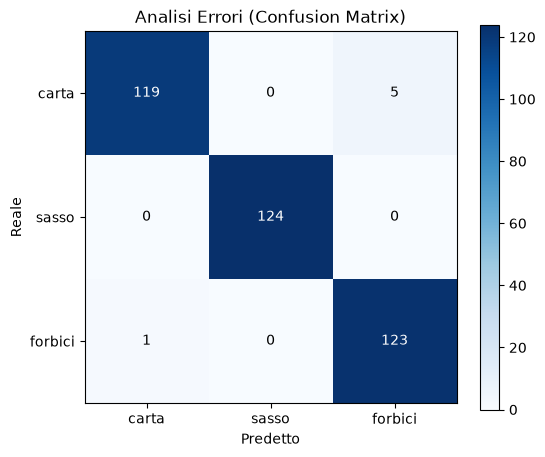

In [13]:
# --- FASE D.1: VALUTAZIONE SUL TEST SET ---
loss, acc = model.evaluate(test_generator, verbose=0)
print(f"[RISULTATO] Accuratezza sul test set: {acc*100:.2f}%")

# --- FASE D.1: PREDIZIONI ---
y_pred_probs = model.predict(test_generator, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# NOTA: con shuffle=False in fase A, y_true è nello stesso ordine delle predizioni;
# target_names segue l'ordine di class_indices stampato in Fase A (paper=0, rock=1, scissors=2)
y_true = test_generator.classes

# --- FASE D.1: REPORT E MATRICE DI CONFUSIONE ---
target_names = ['carta', 'sasso', 'forbici']
print("\n--- PERFORMANCE SUL TEST SET ---")
print(classification_report(y_true, y_pred, target_names=target_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Analisi Errori (Confusion Matrix)")
plt.colorbar()
plt.xticks(range(3), target_names)
plt.yticks(range(3), target_names)
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xlabel("Predetto")
plt.ylabel("Reale")
plt.show()


2. **Test Reale:** Utilizza lo snippet di codice per la webcam (se in ambiente Colab) per scattare una foto della tua mano.

In [17]:
# --- FASE D.2: CARICAMENTO FOTO REALI ---
# NOTA: lavoro in locale su VS Code e non su Colab. Scatto le foto della mia mano e 
# di quella di una bambina su sfondo neutro e le carico con lo stesso
# test_datagen usato per il test set: così il pre-processing (150x150 e 1/255) è identico
# a quello del training, come richiesto dalla traccia.

real_generator = test_datagen.flow_from_directory('foto_reali',
                                                  target_size=IMG_SIZE,
                                                  batch_size=BATCH_SIZE,
                                                  class_mode='categorical',
                                                  shuffle=False) 

# --- FASE D.2: ACCURATEZZA SULLE FOTO REALI ---

loss, acc = model.evaluate(real_generator, verbose=0)
print(f"[RISULTATO] Accuratezza sul set di foto reali: {acc*100:.2f}%")


# --- FASE D.2: ANALISI DEGLI ERRORI ---
def analyze_errors(model, generator):
    probs = model.predict(generator, verbose=0)
    preds = np.argmax(probs, axis=1)
    conf = np.max(probs, axis=1)

    print("\n--- ANALISI QUALITATIVA SULLE FOTO REALI ---")
    for i in range(len(preds)):
        status = "CORRETTO" if preds[i] == generator.classes[i] else "ERRORE"
        print(f"[{status}] File: {generator.filenames[i]}")
        print(f"Reale: {target_names[generator.classes[i]]} | Predetto: {target_names[preds[i]]} (Confidenza: {conf[i]:.2f})\n")

analyze_errors(model, real_generator)


Found 6 images belonging to 3 classes.


[RISULTATO] Accuratezza sul set di foto reali: 83.33%

--- ANALISI QUALITATIVA SULLE FOTO REALI ---
[ERRORE] File: paper\pap1.jpeg
Reale: carta | Predetto: sasso (Confidenza: 0.72)

[CORRETTO] File: paper\pap2.jpeg
Reale: carta | Predetto: carta (Confidenza: 0.58)

[CORRETTO] File: rock\ro1.jpeg
Reale: sasso | Predetto: sasso (Confidenza: 0.97)

[CORRETTO] File: rock\ro2.jpeg
Reale: sasso | Predetto: sasso (Confidenza: 0.79)

[CORRETTO] File: scissors\sci1.jpeg
Reale: forbici | Predetto: forbici (Confidenza: 0.74)

[CORRETTO] File: scissors\sci2.jpeg
Reale: forbici | Predetto: forbici (Confidenza: 0.62)



3. **Analisi del Domain Gap:** Confronta i risultati ottenuti sulle immagini CGI rispetto alle foto reali della tua mano su sfondo neutro.

**Set di foto reali utilizzato**

- **Composizione:** 6 foto, 2 per gesto, organizzate come il dataset in `foto_reali/paper`, `foto_reali/rock`, `foto_reali/scissors`.
- **Persone:** per ogni gesto una foto della mia mano e una della mano di una bambina.
    - `pap1`, `ro1`, `sci1`: la mia mano, inquadrata in orizzontale (entra da sinistra), con disegni sulla pelle, smalto blu e orologio.
    - `pap2`, `ro2`, `sci2`: la mano della bambina, inquadrata in verticale (entra dal basso, come nel dataset CGI), senza decorazioni.
- **Scatto:** fotocamera di uno smartphone Android, ritaglio quadrato 1:1 (2048x2048 px, formato JPEG), muro bianco come sfondo, luce naturale con qualche ombra.
- **Pre-processing:** nessuno manuale; le foto vengono ridimensionate a 150x150 e normalizzate (1/255) dallo stesso `test_datagen` del test set.

Gli output delle celle sono salvati nel notebook, così i risultati della Fase D.2 restano consultabili anche senza le immagini.

**Risultati a confronto**

| Dataset | Immagini | Accuratezza |
|---|---|---|
| Test set CGI | 372 | 98,39% |
| Foto reali della mani | 6 | 83,33% (5 su 6) |

Il calo è evidente, ma con sole 6 foto è causato da un singolo errore: il risultato sulle foto reali va letto come indicativo. 

**Analisi degli errori**

- Sul test CGI gli errori (6 su 372) sono quasi tutti *carta* classificata come *forbici*: due gesti con le dita tese, che si somigliano quando le dita della carta sono un po' separate. Il *sasso* è sempre riconosciuto (precision e recall 1,00).

- Sulle foto reali l'unico errore è `pap1`: una *carta* scattata in orizzontale, con le dita unite e la mano decorata, classificata come *sasso* (confidenza 0,72). Ridotta a 150x150 la sagoma della mano chiusa di lato diventa compatta e somiglia più a un pugno. È un tipo di errore diverso da quelli del test CGI.

- Anche le predizioni corrette sulle foto reali hanno confidenza più bassa (da 0,58 a 0,97, quattro foto su sei sotto 0,80): il modello riconosce i gesti, ma è meno sicuro rispetto alle immagini su cui è stato addestrato.

**Cause del domain gap**

- **Sfondo:** il training ha solo sfondi bianchi puri, le mie foto hanno un muro con texture e con ombre.
- **Mano:** le mani CGI sono pulite e uniformi, nelle mie foto ci sono disegni sulla pelle, smalto e un orologio, elementi mai visti dal modello.
- **Luce:** luce naturale con ombre, invece dell'illuminazione uniforme delle immagini generate al computer.
- **Posa:** le foto verticali, con la mano che entra dal basso come nel dataset, sono tutte corrette; l'errore è su una foto orizzontale.
- **Persona:** le foto verticali sono della mano di una bambina, senza decorazioni; quelle orizzontali sono della mia mano, con disegni, smalto e orologio. Sulla mano della bambina il modello non sbaglia (3 su 3), ma con confidenza più bassa (media 0,66); sulla mia mano sbaglia una foto su tre, mentre le due corrette hanno confidenza più alta (0,97 e 0,74). Con tre foto per serie, e con persona, decorazioni e posa che cambiano tutte insieme, non è possibile stabilire quale di questi fattori causi l'errore.
- **Proporzioni della mano:** secondo la descrizione dell'autore, il dataset contiene mani "from different races, ages, and genders", senza però specificare se includa mani di bambini. In un campione di 30 immagini del training set ho osservato una grande varietà di tonalità della pelle, ma mani dalle proporzioni adulte (dita lunghe rispetto al palmo). Ipotizzo che le mani di bambini siano assenti o poco rappresentate, e che questo spieghi la confidenza più bassa sulla mano della bambina: pur essendo nella posa più simile al dataset (verticale, sfondo chiaro, senza decorazioni), le sue proporzioni la rendono meno "familiare" al modello. Per verificarlo servirebbero più foto di mani di bambini e di adulti nella stessa posa.


**Possibili miglioramenti**

Aggiungere foto reali al training set, oppure ampliare la data augmentation con variazioni di luminosità e colore, così che il modello impari a non dipendere dallo sfondo bianco e dall'illuminazione uniforme.


### 4. Linee Guida e Best Practices

- **Gestione della Memoria:** Assicurati di usare il caricamento a batch per non saturare la RAM.
- **Sfondo:** Ricorda che il modello è addestrato su sfondi bianchi puliti. Per i test reali, usa una parete chiara o uno sfondo uniforme per minimizzare il rumore visivo.
- **Pre-processing:** Verifica che le immagini di test subiscano lo stesso processo di ridimensionamento (150x150) e normalizzazione (1/255) applicato al training set.